In [2]:
import numpy as np

rng = np.random.default_rng(42)

In [3]:
%pip install numpy

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:

import numpy as np
rng = np.random.default_rng(42)

In [5]:
np.__version__

'2.5.2'

In [6]:
population = rng.exponential(scale = 10, size = 100000)

In [7]:
population.mean()

np.float64(10.03496731217151)

In [8]:
population.std()

np.float64(10.052889319196227)

In [9]:
sample = rng.choice(population,size = 30, replace = False)

In [10]:
sample.mean()

np.float64(11.92996118114879)

In [11]:
sample_means = []

for i in range(5000):
    sample = rng.choice(population, size = 30, replace = False)
    sample_means.append(sample.mean())

In [12]:
len(sample_means)

5000

In [13]:
np.mean(sample_means)

np.float64(9.990129353169914)

In [14]:
np.std(sample_means)

np.float64(1.8601694534335589)

In [15]:
%pip install matplotlib

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


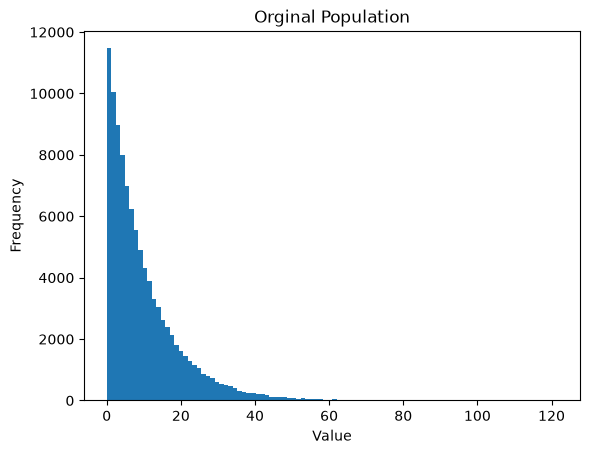

In [16]:
import matplotlib.pyplot as plt

plt.hist(population, bins =100)
plt.xlabel("Value")
plt.ylabel("Frequency")
plt.title("Orginal Population")
plt.show()

In [17]:
import matplotlib.pyplot as plt

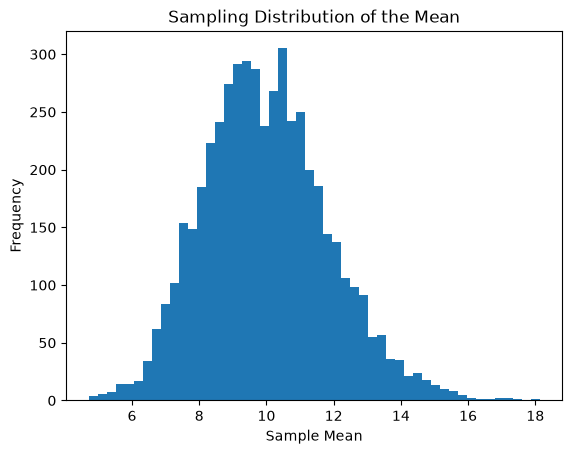

In [18]:
plt.hist(sample_means, bins=50)
plt.xlabel("Sample Mean")
plt.ylabel("Frequency")
plt.title("Sampling Distribution of the Mean")
plt.show()

In [19]:
sample_means_100 = []

for i in range(5000):
    sample = rng.choice(population, size=100, replace=False)
    sample_means_100.append(sample.mean())

In [20]:
np.std(sample_means_100)

np.float64(1.0280917167596184)

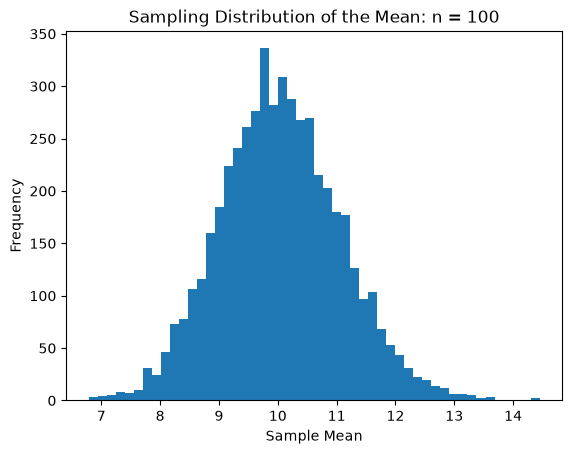

In [21]:
plt.hist(sample_means_100, bins=50)
plt.xlabel("Sample Mean")
plt.ylabel("Frequency")
plt.title("Sampling Distribution of the Mean: n = 100")
plt.show()

In [22]:
sample = rng.choice(population, size=100, replace=False)

In [23]:
sample_mean = sample.mean()
sample_sd = sample.std(ddof=1)
se = sample_sd / np.sqrt(len(sample))

lower = sample_mean - 1.96 * se
upper = sample_mean + 1.96 * se

print("Sample mean:", sample_mean)
print("Sample SD:", sample_sd)
print("Standard error:", se)
print("95% CI:", lower, upper)

Sample mean: 8.572573613160483
Sample SD: 8.01689315824079
Standard error: 0.8016893158240791
95% CI: 7.0012625541452875 10.143884672175677


In [24]:
population.mean() >= lower and population.mean() <= upper

np.True_

In [25]:
covered = 0
n_intervals = 5000

for i in range(n_intervals):
    sample = rng.choice(population, size=100, replace=False)

    sample_mean = sample.mean()
    sample_sd = sample.std(ddof=1)
    se = sample_sd / np.sqrt(100)

    lower = sample_mean - 1.96 * se
    upper = sample_mean + 1.96 * se

    if population.mean() >= lower and population.mean() <= upper:
        covered += 1

In [26]:
coverage = covered / n_intervals
coverage

0.9402

In [27]:
coverage * 100

94.02000000000001